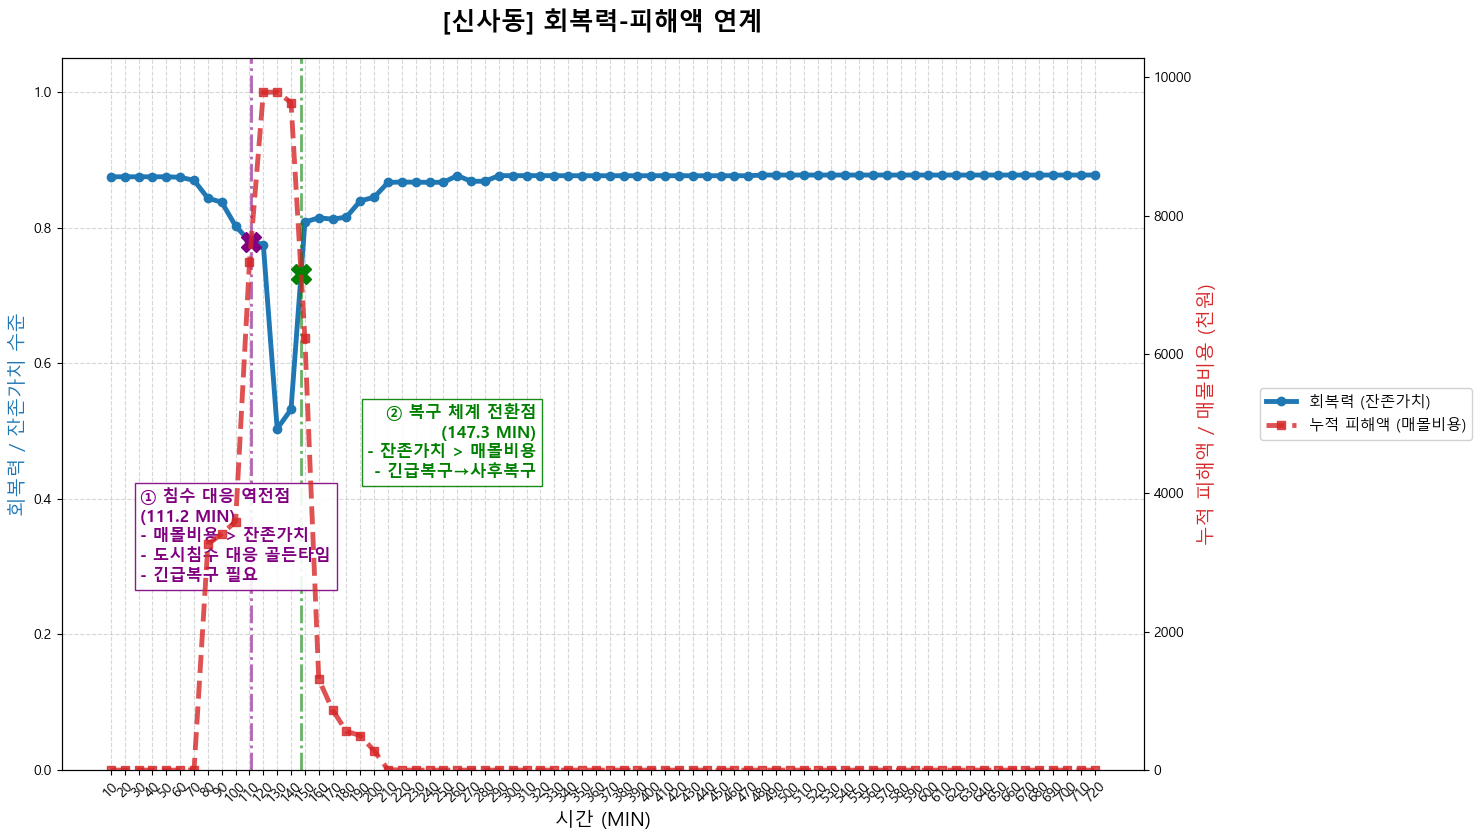

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import glob
import re
import os
import numpy as np

# --- 1. 환경 설정 ---
if os.name == 'nt':
    plt.rcParams['font.family'] = 'Malgun Gothic'
else:
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

file_pattern = 'H_*MIN_region_results_final.csv'
target_region = '신사동'  # 현재 수기로 행정동명 변경하여 출력하고 있습니다. 

# --- 2. 데이터 수집 ---
file_list = glob.glob(file_pattern)
data = []

for file in file_list:
    match = re.search(r'(\d+)MIN', file)
    if match:
        time_min = int(match.group(1))
        # UTF-8 인코딩 우선 시도
        try:
            df = pd.read_csv(file, encoding='utf-8')
        except UnicodeDecodeError:
            try:
                df = pd.read_csv(file, encoding='cp949')
            except UnicodeDecodeError:
                df = pd.read_csv(file, encoding='euc-kr')
            
        region_col = 'ADM_NM_y'
        damage_col = '피해액 (천원)'
        
        if region_col in df.columns and 'Resilience' in df.columns and damage_col in df.columns:
            df_filtered = df[df[region_col] == target_region].copy()
            df_filtered = df_filtered.dropna(subset=['Resilience'])
            
            for _, row in df_filtered.iterrows():
                damage_val = str(row[damage_col]).replace(',', '')
                try:
                    damage = float(damage_val)
                except ValueError:
                    damage = 0.0
                data.append({'Time': time_min, 'Resilience': row['Resilience'], 'Damage': damage})

df_all = pd.DataFrame(data)

if df_all.empty:
    print(f"'{target_region}'의 데이터가 없습니다. 지역명을 다시 확인해주세요.")
else:
    # 데이터 정렬 및 피벗
    df_all = df_all.sort_values(by='Time').set_index('Time')
    times = df_all.index
    res_values = df_all['Resilience']
    dam_values = df_all['Damage']
    
    # max_damage 산출 및 정규화
    max_damage = dam_values.max() if dam_values.max() > 0 else 1
    normalized_damage = dam_values / max_damage
    
    # ★ 누적 기회비용(면적) 계산: 적분 (1.0 - Resilience) dt
    loss_values = 1.0 - res_values
    total_opportunity_cost = np.trapz(loss_values.values, x=times.values)
    
    # 동적 분석 1: 임계점 (1.0 미만으로 떨어지는 최초 시점)
    tipping_times = res_values[res_values < 1.0].index
    has_tipping_point = len(tipping_times) > 0
    tipping_point = tipping_times[0] if has_tipping_point else None

    # 동적 분석 2: 경제적 충격 역전점 (1차, 2차 교차점 계산)
    crossover1_point, crossover1_res_val = None, None
    crossover2_point, crossover2_res_val = None, None
    has_crossover1, has_crossover2 = False, False
    
    diff = normalized_damage - res_values
    for i in range(len(times) - 1):
        # 1차 교차점: 매몰비용이 잔존가치를 역전 (diff가 음수에서 양수로)
        if not has_crossover1 and diff.iloc[i] < 0 and diff.iloc[i+1] >= 0:
            x1, x2 = times[i], times[i+1]
            y1_res, y2_res = res_values.iloc[i], res_values.iloc[i+1]
            y1_dam, y2_dam = normalized_damage.iloc[i], normalized_damage.iloc[i+1]
            num, den = y1_res - y1_dam, (y1_res - y1_dam) - (y2_res - y2_dam)
            if den != 0:
                fraction = num / den
                crossover1_point = round(x1 + (x2 - x1) * fraction, 1)
                crossover1_res_val = y1_res + (y2_res - y1_res) * fraction
                has_crossover1 = True
                
        # 2차 교차점: 잔존가치가 매몰비용을 재역전 (diff가 양수에서 음수로)
        elif has_crossover1 and not has_crossover2 and diff.iloc[i] > 0 and diff.iloc[i+1] <= 0:
            x1, x2 = times[i], times[i+1]
            y1_res, y2_res = res_values.iloc[i], res_values.iloc[i+1]
            y1_dam, y2_dam = normalized_damage.iloc[i], normalized_damage.iloc[i+1]
            num, den = y1_res - y1_dam, (y1_res - y1_dam) - (y2_res - y2_dam)
            if den != 0:
                fraction = num / den
                crossover2_point = round(x1 + (x2 - x1) * fraction, 1)
                crossover2_res_val = y1_res + (y2_res - y1_res) * fraction
                has_crossover2 = True
            
    # --- 3. 시각화 ---
    fig, ax1 = plt.subplots(figsize=(15, 8.5))
    ax2 = ax1.twinx()
    
    color_res = '#1f77b4' 
    color_dam = '#d62728' 
    
    line1, = ax1.plot(times, res_values, linestyle='-', marker='o', markersize=6, linewidth=3.5, color=color_res, label='회복력 (잔존가치)')
    line2, = ax2.plot(times, dam_values, linestyle='--', marker='s', markersize=6, linewidth=3.5, color=color_dam, alpha=0.8, label='누적 피해액 (매몰비용)')
    
    ax1.set_ylim([0.0, 1.05]) 
    ax2.set_ylim([0.0, max_damage * 1.05])
    
  
        
    # 제1교차점 표출
    if has_crossover1:
        ax1.plot(crossover1_point, crossover1_res_val, marker='X', markersize=14, color='purple', zorder=5)
        ax1.axvline(x=crossover1_point, color='purple', linestyle='-.', linewidth=2, alpha=0.6)
        ax1.text(crossover1_point - 80, crossover1_res_val - 0.5, 
                 f'① 침수 대응 역전점\n({crossover1_point} MIN)\n- 매몰비용 > 잔존가치\n- 도시침수 대응 골든타임\n- 긴급복구 필요', 
                 fontsize=12, color='purple', fontweight='bold', bbox=dict(facecolor='white', alpha=0.9, edgecolor='purple'))

    # ★ 제2교차점 표출 (복구 손익분기점)
    if has_crossover2:
        ax1.plot(crossover2_point, crossover2_res_val, marker='X', markersize=14, color='green', zorder=5)
        ax1.axvline(x=crossover2_point, color='green', linestyle='-.', linewidth=2, alpha=0.6)
        ax1.text(crossover2_point + 170, crossover2_res_val - 0.3, 
                 f'② 복구 체계 전환점\n({crossover2_point} MIN)\n- 잔존가치 > 매몰비용\n- 긴급복구→사후복구', 
                 fontsize=12, color='green', fontweight='bold', ha='right', bbox=dict(facecolor='white', alpha=0.9, edgecolor='green'))

    ax1.set_title(f'[{target_region}] 회복력-피해액 연계', fontsize=18, fontweight='bold', pad=20)
    ax1.set_xlabel('시간 (MIN)', fontsize=14)
    ax1.set_ylabel('회복력 / 잔존가치 수준', fontsize=14, color=color_res)
    ax2.set_ylabel('누적 피해액 / 매몰비용 (천원)', fontsize=14, color=color_dam)
    
    ax1.set_xticks(times)
    ax1.tick_params(axis='x', rotation=45)
    ax1.grid(True, linestyle='--', alpha=0.5)
    
    lines = [line1, line2]
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='center left', bbox_to_anchor=(1.1, 0.5), fontsize=11, framealpha=0.9)
    
    plt.tight_layout()
    plt.show()